In [3]:
%matplotlib inline

import numpy as np
import pandas as pd
from ISLP import load_data
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from functions_p3 import (
    comparar_modelos, observacion_cercana_umbral,
    valores_coalicion, shapley_por_ordenes, verificar_eficiencia,
    explicar_shap, comparar_shap, graficar_cascada,
    estabilidad_lime, resumir_lime, ice_individual, contrafactual_ice,
    graficar_resumen_shap, graficar_dependencia_shap, comparar_importancias,
)

SEMILLA = 2026

/Users/torodriguezt/entornos/estadistica-II/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
default = load_data("Default")

X = pd.DataFrame({"balance": default["balance"], "income": default["income"],
                  "student":(default["student"] == "Yes").astype(int)})

y = (default["default"] == "Yes").astype(int)

X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size = 0.3, random_state = SEMILLA)

In [11]:
bosques = RandomForestClassifier(n_estimators = 500, min_samples_leaf = 20, random_state = SEMILLA, n_jobs = -1)

logistica = make_pipeline(StandardScaler(), LogisticRegression(penalty = None))

In [14]:
errores = comparar_modelos({"Bosque Aleatorio": bosques, "Regresion Logistica": logistica}, X_ent, y_ent, X_pru, y_pru)

print(errores)
print("Error de predecir siempre que no cumple", y_pru.mean())

                     Tasa de error
Bosque Aleatorio          0.028000
Regresion Logistica       0.028333
Error de predecir siempre que no cumple 0.034333333333333334


/Users/torodriguezt/entornos/estadistica-II/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [17]:
x0 = observacion_cercana_umbral(bosques, X_pru, umbral = 0.5)
v = valores_coalicion(bosques, x0, X_ent)

In [19]:
ordenes = shapley_por_ordenes(v, X.columns)
phi = ordenes.mean()
eficiencia = verificar_eficiencia(v, ordenes)

print(x0, v, ordenes, phi, eficiencia, sep="\n")

          balance        income  student
6242  1954.321689  17137.473724        1
{}                            0.032735
{balance}                     0.587691
{income}                      0.034428
{student}                     0.041702
{balance, income}             0.514032
{balance, student}            0.472306
{income, student}             0.025601
{balance, income, student}    0.498247
dtype: float64
                           balance    income   student
orden                                                 
balance, income, student  0.554955 -0.073659 -0.015785
balance, student, income  0.554955  0.025940 -0.115384
income, balance, student  0.479604  0.001692 -0.015785
income, student, balance  0.472646  0.001692 -0.008827
student, balance, income  0.430605  0.025940  0.008967
student, income, balance  0.472646 -0.016101  0.008967
balance    0.494235
income    -0.005749
student   -0.022975
dtype: float64
base            3.273527e-02
suma_aportes    4.655114e-01
prediccion      4.

           manual      shap  shap_100
balance  0.494235  0.494235  0.488844
income  -0.005749 -0.005749 -0.005678
student -0.022975 -0.022975 -0.022648
phi_0    0.032735  0.032735  0.037728


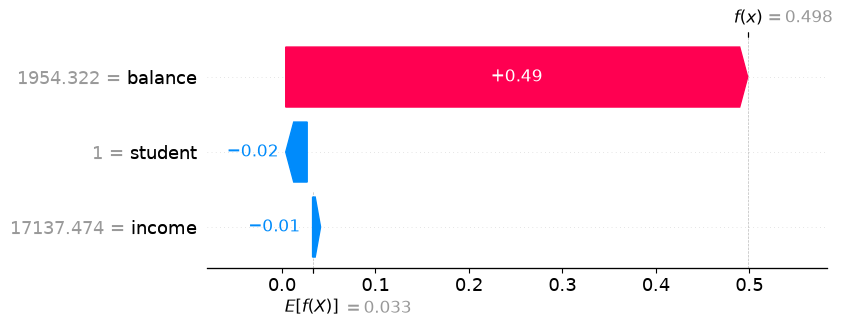

In [21]:
shap_x0 = explicar_shap(bosques, x0, X_ent)
shap_x0_100 = explicar_shap(bosques, x0, X_ent, n_ref = 100)
comparacion_shap = comparar_shap(v, ordenes, shap=shap_x0, shap_100 = shap_x0_100)

print(comparacion_shap)
graficar_cascada(shap_x0)

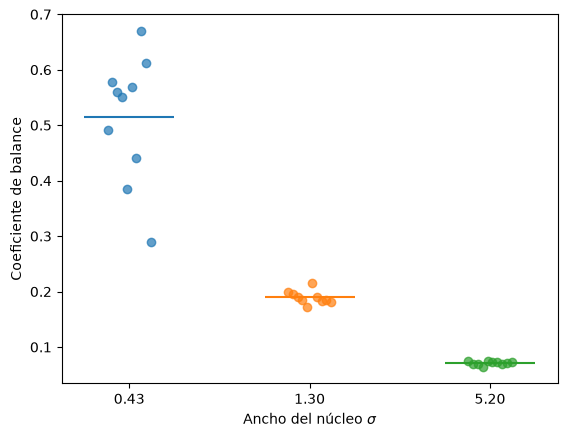

             media      desv    minimo    maximo  intercepto        R2  \
ancho                                                                    
0.433013  0.514697  0.114225  0.289412  0.670409    0.430548  0.836155   
1.299038  0.189471  0.011751  0.172126  0.215019    0.314701  0.714168   
5.196152  0.070856  0.003159  0.064521  0.074503    0.197124  0.428465   

           n_efectivo  
ancho                  
0.433013    11.654048  
1.299038   209.547547  
5.196152  2877.784453  


In [24]:
anchos = np.array([0.25, 0.75, 3])*np.sqrt(X.shape[1])

lime = estabilidad_lime(bosques, x0, X_ent, anchos, "balance", M = 3000, n_semillas = 10)
resumen_lime = resumir_lime(lime, "balance")

print(resumen_lime)

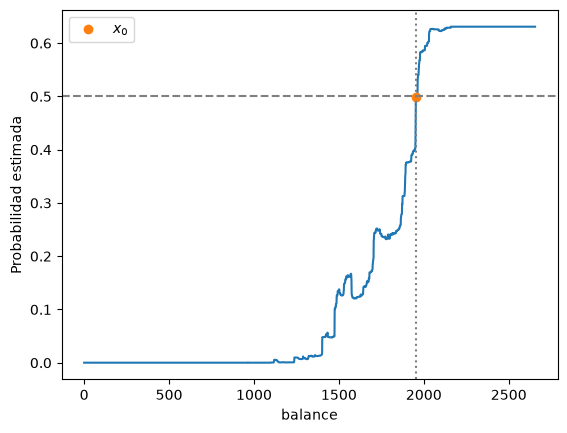

{'cruces': [1956.5], 'intervalos_cruce': [(1956.0, 1957.0)], 'cruce_cercano': 1956.5, 'contrafactual': 1954.32168919689, 'cambio': 0.0, 'probabilidad': 0.4982466354431483, 'ya_cumple': True}
{'cruces': [1956.5], 'intervalos_cruce': [(1956.0, 1957.0)], 'cruce_cercano': 1956.5, 'contrafactual': 1957.0, 'cambio': 2.67831080310998, 'probabilidad': 0.5012366942827762, 'ya_cumple': False}


In [29]:
grilla = np.arange(0, X["balance"].max() + 1, 1.0)
ice_x0 = ice_individual(bosques, x0, "balance", grilla, umbral = 0.5)

contrafactual = contrafactual_ice(ice_x0, x0["balance"].item(), umbral = 0.5)
print(contrafactual)


opuesto = contrafactual_ice(ice_x0, x0["balance"].item(), umbral = 0.5, objetivo = "mayor_igual")
print(opuesto)


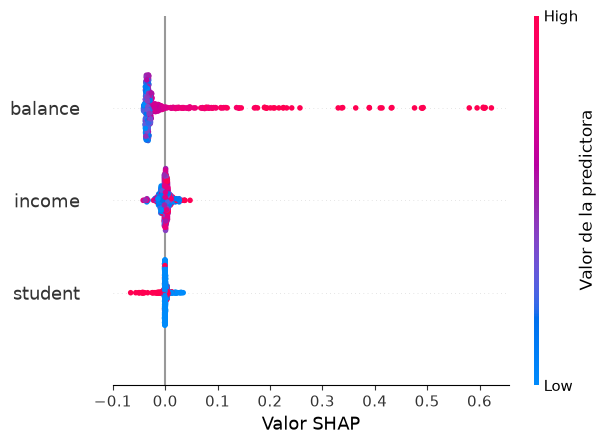

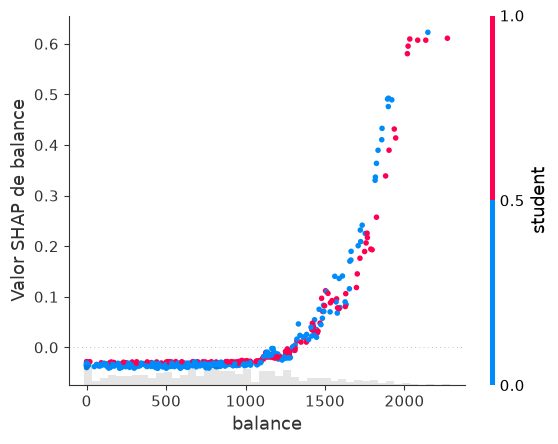

         media_abs_shap  permutacion_error  desv_error  permutacion_brier  \
balance        0.058198           0.023533    0.001343           0.022228   
income         0.006374           0.000333    0.000558           0.000194   
student        0.004089           0.000600    0.000389           0.000732   

         desv_brier  impureza  
balance    0.000561  0.911804  
income     0.000208  0.080909  
student    0.000117  0.007286  


In [32]:
X_500 = X_pru.sample(500, random_state = SEMILLA)
shap_500 = explicar_shap(bosques, X_500, X_ent, n_ref = 200)

graficar_resumen_shap(shap_500)
graficar_dependencia_shap(shap_500, "balance", color = "student")

importancia = comparar_importancias(bosques, X_pru, y_pru, shap_500)
print(importancia)